# Task 4 — Voiceprint Verification Model

**Goal:** given a voice sample, decide whether it belongs to the person the face model just recognised.

**Approach**
1. Train a speaker classifier on `audio_features.csv` (MFCCs, roll-off, spectral and energy statistics).
2. Evaluate with **leave-one-recording-out** cross-validation, grouped by `source_file`, so an augmented copy of a
   recording is never in train while its original is in test.
3. Report **accuracy, macro F1 and log-loss** (the metrics the brief asks for).
4. Build a **voiceprint** per member (mean standardised feature vector) and a **distance threshold** so unknown voices are
   rejected, then wrap everything in `verify_voice()` for the command-line app.

`duration_s` and `energy` are excluded from training: they depend on the phrase and recording volume, not on who is speaking.

## 1. Setup

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import classification_report

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from scripts import voice_model as vm

## 2. Load the audio feature table

In [2]:
df, feature_cols = vm.load_data(ROOT / "audio_features.csv")
print(f"{len(df)} rows | {df.member.nunique()} members | {df.source_file.nunique()} recordings | {len(feature_cols)} features used")
display(pd.crosstab(df.member, df.augmentation))

72 rows | 4 members | 8 recordings | 38 features used


augmentation,background_noise,original,pitch_down,pitch_up,time_stretch_fast,time_stretch_slow
member,,,,,,
Esther,4,4,4,4,4,4
Laura,4,4,4,4,4,4
Rwema,2,2,2,2,2,2
Yusuf,2,2,2,2,2,2


## 3. Compare models (leave-one-recording-out)

Each fold hides **both the original and all augmented versions of one recording** and trains on the other 7.
The held-out recording is also a *different phrase* from the member's other recording, so this is a deliberately
demanding test. Two models are compared; the best by macro-F1 (ties broken by lower log-loss) is selected.

In [3]:
table, results = vm.compare_models(df, feature_cols)
display(table.round(3))
best = results[table.iloc[0].model]
print("Selected:", best["model"])
print("Originals only:", {k: round(v, 3) for k, v in best["originals_only"].items()})

,model,accuracy,f1_macro,log_loss,accuracy_originals_only
0,random_forest,0.681,0.470,0.820,0.667
1,logistic_regression,0.667,0.404,3.271,0.667


Selected: random_forest
Originals only: {'accuracy': 0.667, 'f1_macro': 0.422, 'log_loss': 0.901, 'n': 12}


### Confusion matrix and per-member report

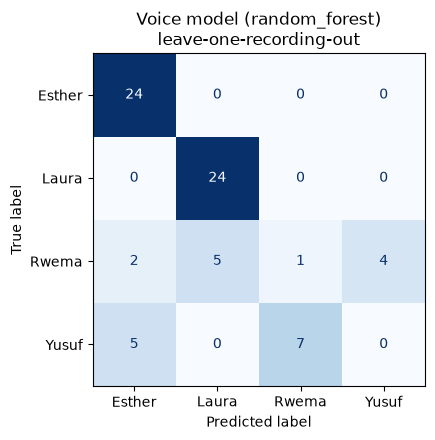

              precision    recall  f1-score   support

      Esther       0.77      1.00      0.87        24
       Laura       0.83      1.00      0.91        24
       Rwema       0.12      0.08      0.10        12
       Yusuf       0.00      0.00      0.00        12

    accuracy                           0.68        72
   macro avg       0.43      0.52      0.47        72
weighted avg       0.55      0.68      0.61        72



In [4]:
fig = vm.plot_confusion(df, best, ROOT / "reports" / "voice_confusion_matrix.png")
plt.show()
pred = best["classes"][best["proba"].argmax(axis=1)]
print(classification_report(df.member, pred, zero_division=0))

## 4. Train the final model, set the distance threshold, save

`data/unauthorized/` should contain recordings of people **not** in the team. If it exists, the threshold is calibrated on
genuine (held-out) vs. unauthorized distances to the voiceprint; otherwise a provisional value is used and clearly flagged.
A classifier's confidence is *not* used to spot strangers because it always favours its closest member.

c:\Users\user\machineLearningPipeline_formative2MultimodalDataPreprocessingAssignment\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


              model  accuracy  f1_macro  log_loss  accuracy_originals_only
      random_forest  0.680556  0.469597  0.819919                 0.666667
logistic_regression  0.666667  0.403618  3.270678                 0.666667

Selected: random_forest
CV (all rows):        {'accuracy': 0.6805555555555556, 'f1_macro': 0.46959691252144087, 'log_loss': 0.8199193723974485, 'n': 72}
CV (originals only):  {'accuracy': 0.6666666666666666, 'f1_macro': 0.4222222222222222, 'log_loss': 0.9014136542816432, 'n': 12}
Distance threshold: 16.002  [calibrated: genuine and unauthorized recordings are separable]
Genuine held-out recordings accepted: 100% of 8
Unauthorized recordings rejected: 100% of 2
Saved model -> c:\Users\user\machineLearningPipeline_formative2MultimodalDataPreprocessingAssignment\models\voice_model.joblib


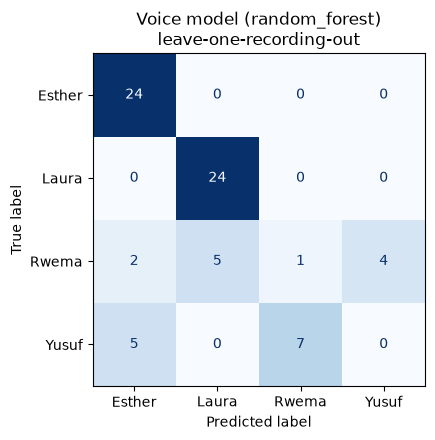

In [5]:
bundle = vm.train_and_save(
    csv_path=ROOT / "audio_features.csv",
    model_path=ROOT / "models" / "voice_model.joblib",
    unauthorized_dir=ROOT / "data" / "unauthorized",
    report_dir=ROOT / "reports",
)

## 5. Verification demo

In [6]:
bundle = vm.load_bundle(ROOT / "models" / "voice_model.joblib")
audio = vm.af.list_audio_files(ROOT / "data" / "audio")

def show(r): print(f"{'APPROVED' if r['approved'] else 'DENIED  '} | claimed={r['claimed_member']:<8} predicted={r['predicted_member']:<8} conf={r['confidence']:.2f} dist={r['distance_to_claimed']}/{r['distance_threshold']} | {r['reason']}")

# 1) genuine: each member's own recording, claiming their own identity
for f in audio[:4]:
    member, _ = vm.af.parse_filename(f)
    show(vm.verify_voice(f, member, bundle))

DENIED   | claimed=Esther   predicted=Yusuf    conf=0.50 dist=38.047/16.002 | unknown voice (not close to any enrolled member)
DENIED   | claimed=Esther   predicted=Yusuf    conf=0.58 dist=38.712/16.002 | unknown voice (not close to any enrolled member)
DENIED   | claimed=Laura    predicted=Yusuf    conf=0.32 dist=23.907/16.002 | unknown voice (not close to any enrolled member)
DENIED   | claimed=Laura    predicted=Yusuf    conf=0.40 dist=23.77/16.002 | unknown voice (not close to any enrolled member)


In [7]:
# 2) wrong claim: someone's voice while claiming to be somebody else
a, b = audio[0], audio[-1]
claimed = vm.af.parse_filename(b)[0]
print(f"{a.name} claiming to be {claimed}:")
show(vm.verify_voice(a, claimed, bundle))

Esther 1.aac claiming to be Yusuf:
DENIED   | claimed=Yusuf    predicted=Yusuf    conf=0.50 dist=37.818/16.002 | unknown voice (not close to any enrolled member)


In [8]:
# 3) unauthorized voice (not enrolled) claiming to be a member
unauth = vm.af.list_audio_files(ROOT / "data" / "unauthorized") if (ROOT / "data" / "unauthorized").exists() else []
if unauth:
    for f in unauth:
        show(vm.verify_voice(f, vm.af.parse_filename(audio[0])[0], bundle))
else:
    print("No recordings in data/unauthorized/ yet — add one or two (Task 6 needs this demo).")

DENIED   | claimed=Esther   predicted=Yusuf    conf=0.55 dist=37.677/16.002 | unknown voice (not close to any enrolled member)
DENIED   | claimed=Esther   predicted=Yusuf    conf=0.43 dist=28.679/16.002 | unknown voice (not close to any enrolled member)


## 6. Limitations to state in the report
* Only 2 recordings per member: metrics are indicative, not a precise estimate of real-world accuracy.
* The model recognises **who** is speaking, not **what** is said, so it does not check the phrase itself (that would need speech recognition).
* A closed-set classifier always picks its closest member, so rejection relies on the voiceprint-distance threshold. Calibrate it with real unauthorized recordings; the provisional value is only a starting point.
* Recordings from other microphones/rooms will shift the features; augmentation (noise, pitch, speed) only partly covers that.